In [1]:
import sys
# sys.path.insert(0, '../../Utilities/')

# from jax.example_libraries import optimizers
import jax.numpy as jnp
import numpy as np
from jax import grad, jit, vmap, value_and_grad, hessian
from jax import random
from functools import partial
import flax.linen as nn
import jax
import optax
import pickle
from datetime import datetime
import os
import numpy as np
from scipy import sparse
import time
from jax import grad, hessian, jit, vmap, pmap
from jax.tree_util import tree_leaves
from datetime import datetime
import matplotlib.pyplot as plt
import pickle
import flax.linen as nn
import optax
import optax.tree_utils as otu
from NN_class import MLP
from my_helpers import plot_u_theta, plot_kh, plot_loss_history
from functools import partial
from Pwp_class import PiecewiseLinearPolynomials
from minmax_opt_class import pytree_l2_norm, MinMaxOptProb
from seq_minmax_opt_class import SeqMinMaxOptProb


import matplotlib.pyplot as plt
import scipy.io
from scipy.interpolate import griddata

import time
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1 import make_axes_locatable
import mpmath

# Generate key which is used to generate random numbers
key = random.PRNGKey(1)

In [2]:
def u0(x):
    return -jnp.sin(jnp.pi*x)

# Boundary at x=-1
def u1(x):
    return 0
vmap_u1 = vmap(u1, in_axes=0, out_axes=0)

# Boundary at x=2
def u2(x):
    return 0
vmap_u2 = vmap(u2, in_axes=0, out_axes=0)

def res_visc(u_quad, u_t, u_x, u_xx, nu):
    return u_t + u_quad * u_x - nu*u_xx
def res(u_quad, u_t, u_x):
    return u_t + u_quad * u_x


t_min = 0
t_max = 1
x_min = -1
x_max = 1
Nt = 101
Nx = 301
layers = [2, 50, 50, 50, 50, 50, 1]
hidden_dims_list = [layers[1:-1]]

# Domain bounds
lb = jnp.array([t_min, x_min])
ub = jnp.array([t_max, x_max])

In [4]:
notes = '''This notebook is for computing Burgers equation with sin init, \n
featured with initial gamma = 0.0, f_opt_kh = 1, use_a = True, and L1_regularization = 0.\n
We use warmup_exponential_decay_schedule for the learning rate.\n
We use normal sampling to optimize k_h with sigma = 0.2.
In this copy, we train 50000 epoches. '''
print(notes)

This notebook is for computing Burgers equation with sin init, 

featured with initial gamma = 0.0, f_opt_kh = 1, use_a = True, and L1_regularization = 0.

We use warmup_exponential_decay_schedule for the learning rate.

We use normal sampling to optimize k_h with sigma = 0.2.
In this copy, we train 50000 epoches. 


In [5]:
seq_trainer = SeqMinMaxOptProb(
    num_segments=5,
    total_t_min=t_min,
    total_t_max=t_max,
    N_t=16,
    N_x=32,
    hidden_dims_list=hidden_dims_list,
    seed=0, sigma=0.1, N_perturb=10000, N_bc=2048, N_ic=4096, k_h_rf_times=2, 
    u0=u0, u1=vmap_u1, u2=vmap_u2, project="seq_minmax_burgers_sin_wave",
    gamma=0.0, N_test_gamma=1000, adjust_gamma=True,
    L1_regularization=0, sampling_method='normal', notes=notes, lambda_tv=1.0, 
    init_lrs=[1e-3, 1e-3, 1e-3], grade_epochs=[10, 10, 10], decay_rates=[1e-3, 1e-3, 1e-3],
    res=res, total_grade=1, k=0,
)



Plotting before training segment 1/3 (t = [0.0000, 1.0000])


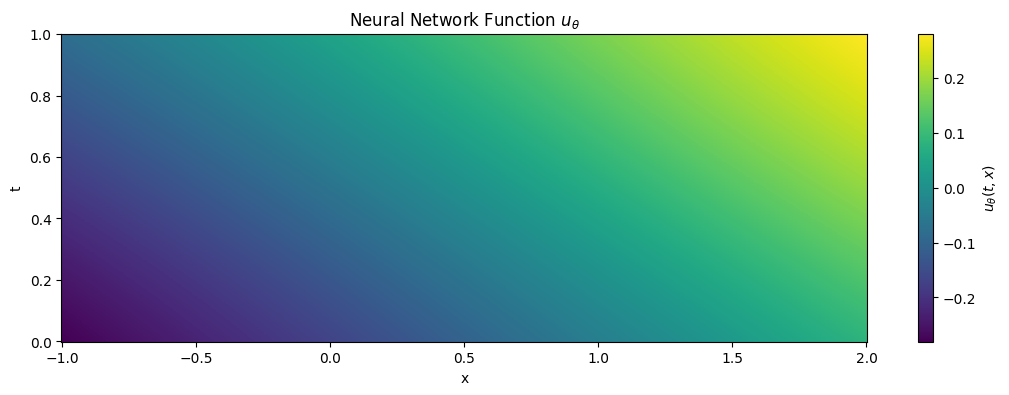


Training segment 1/3 (t = [0.0000, 1.0000])

Starting Train Stage
Iteration 0, lambda_ic: 1.64653373, lambda_bc: 1.50510383, lambda_r: 1.04269671.
Iteration 0, before maximize k_h, loss: 0.62185860, 0.49710038.
Iteration 0, after maximize k_h, loss: 0.62185860, 0.49710038.
Train Iteration 0, Loss_int: 0.62185889, Loss_bc: 0.49710038
Iteration 100, before maximize k_h, loss: 0.00410645, 0.29246446.
Iteration 100, after maximize k_h, loss: 0.00421402, 0.29246446.
Train Iteration 100, Loss_int: 0.00421402, Loss_bc: 0.29246446
Iteration 200, before maximize k_h, loss: 0.01545692, 0.29101655.
Iteration 200, after maximize k_h, loss: 0.01545876, 0.29101655.
Train Iteration 200, Loss_int: 0.01545877, Loss_bc: 0.29101655
Iteration 300, before maximize k_h, loss: 0.01180728, 0.29268903.
Iteration 300, after maximize k_h, loss: 0.01180969, 0.29268903.
Train Iteration 300, Loss_int: 0.01180969, Loss_bc: 0.29268903
Iteration 400, before maximize k_h, loss: 0.00045826, 0.29139441.
Iteration 400, a

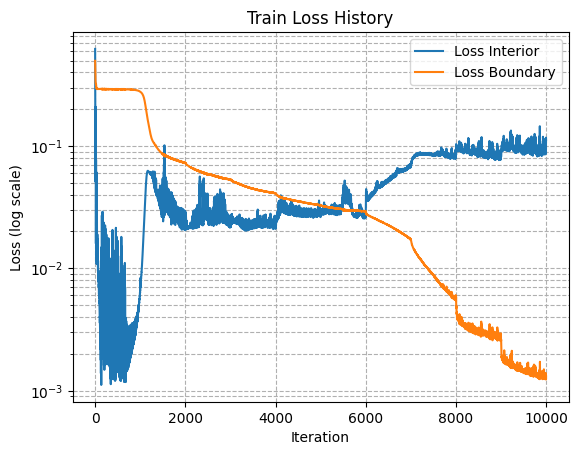


Plotting after training segment 1/3 (t = [0.0000, 1.0000])


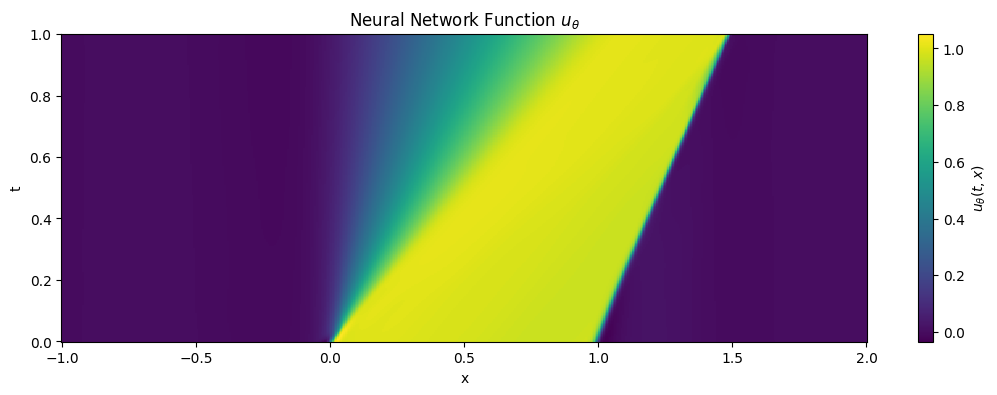


Plotting before training segment 2/3 (t = [1.0000, 2.0000])


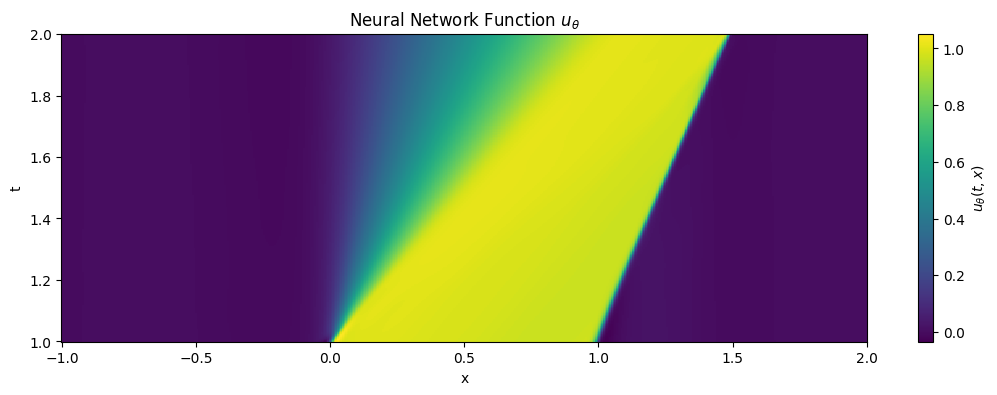


Training segment 2/3 (t = [1.0000, 2.0000])

Starting Train Stage
Iteration 0, lambda_ic: 1.72838259, lambda_bc: 57.40439224, lambda_r: 1.01395845.
Iteration 0, before maximize k_h, loss: 0.09971491, 0.26654014.
Iteration 0, after maximize k_h, loss: 0.09966963, 0.26654014.
Train Iteration 0, Loss_int: 0.09966920, Loss_bc: 0.26654011
Iteration 100, before maximize k_h, loss: 0.04289566, 0.08585156.
Iteration 100, after maximize k_h, loss: 0.05457377, 0.08585156.
Train Iteration 100, Loss_int: 0.05457351, Loss_bc: 0.08585156
Iteration 200, before maximize k_h, loss: 0.02907862, 0.06648628.
Iteration 200, after maximize k_h, loss: 0.03939025, 0.06648628.
Train Iteration 200, Loss_int: 0.03939023, Loss_bc: 0.06648628
Iteration 300, before maximize k_h, loss: 0.02125167, 0.05804658.
Iteration 300, after maximize k_h, loss: 0.02966204, 0.05804658.
Train Iteration 300, Loss_int: 0.02966196, Loss_bc: 0.05804658
Iteration 400, before maximize k_h, loss: 0.01314598, 0.05387323.
Iteration 400, 

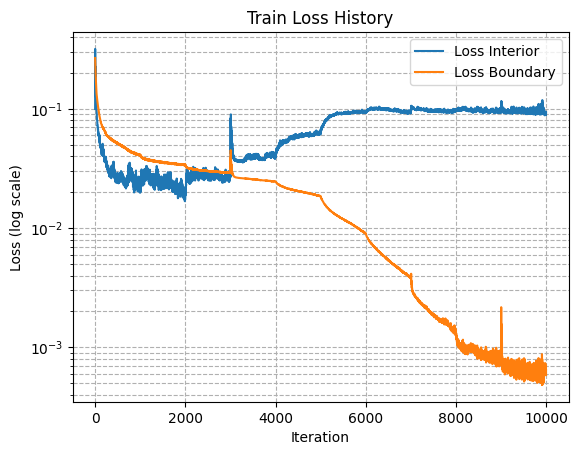


Plotting after training segment 2/3 (t = [1.0000, 2.0000])


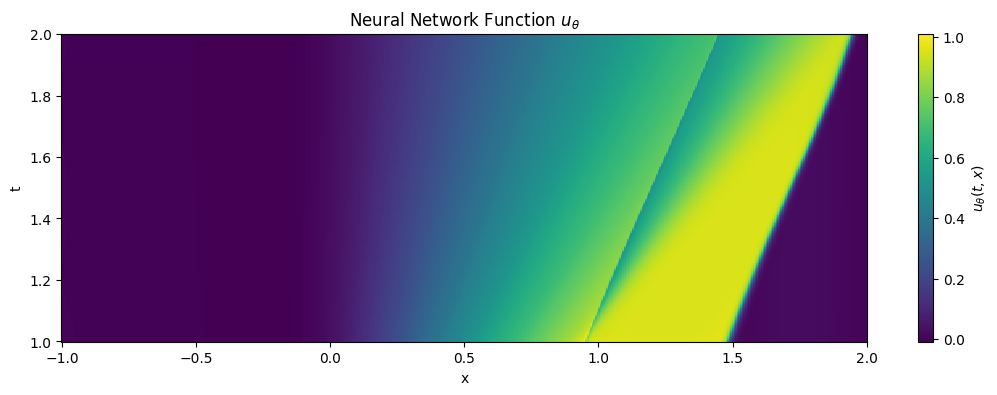


Plotting before training segment 3/3 (t = [2.0000, 3.0000])


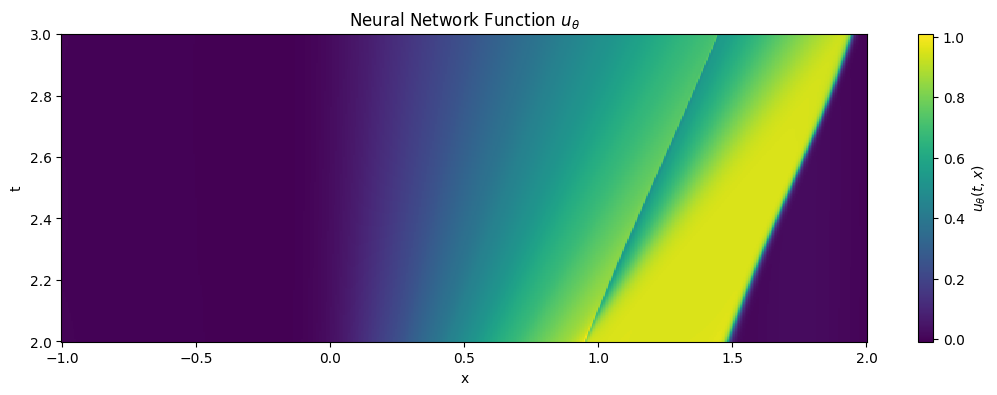


Training segment 3/3 (t = [2.0000, 3.0000])

Starting Train Stage
Iteration 0, lambda_ic: 1.75297189, lambda_bc: 77.33691406, lambda_r: 1.01344883.
Iteration 0, before maximize k_h, loss: 0.09052452, 0.13379174.
Iteration 0, after maximize k_h, loss: 0.09279414, 0.13379174.
Train Iteration 0, Loss_int: 0.09279452, Loss_bc: 0.13379171
Iteration 100, before maximize k_h, loss: 0.05030971, 0.08041900.
Iteration 100, after maximize k_h, loss: 0.06352544, 0.08041900.
Train Iteration 100, Loss_int: 0.06352534, Loss_bc: 0.08041900
Iteration 200, before maximize k_h, loss: 0.03246774, 0.06454587.
Iteration 200, after maximize k_h, loss: 0.04578143, 0.06454587.
Train Iteration 200, Loss_int: 0.04578118, Loss_bc: 0.06454585
Iteration 300, before maximize k_h, loss: 0.02915062, 0.05511947.
Iteration 300, after maximize k_h, loss: 0.03366934, 0.05511947.
Train Iteration 300, Loss_int: 0.03366962, Loss_bc: 0.05511946
Iteration 400, before maximize k_h, loss: 0.01184160, 0.05199422.
Iteration 400, 

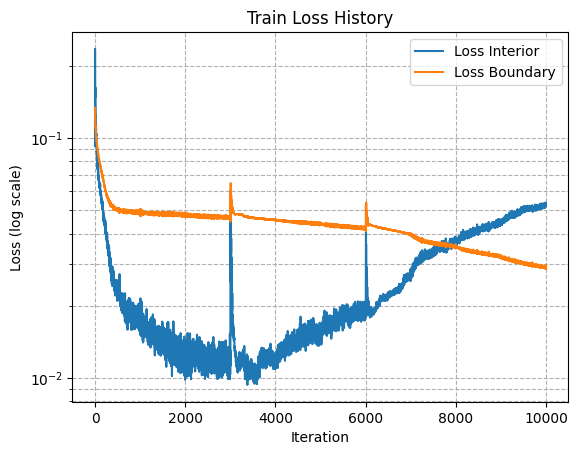


Plotting after training segment 3/3 (t = [2.0000, 3.0000])


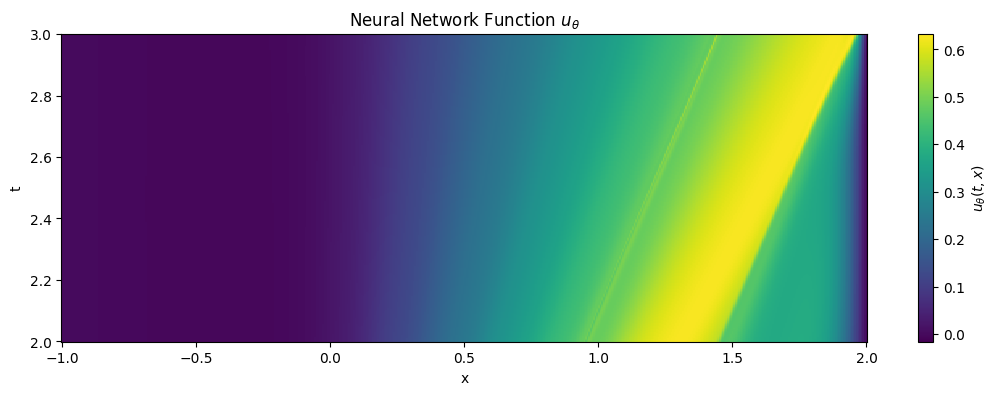


Plotting combined output across all segments from t=0 to total_t_max


NameError: name 'plt' is not defined

In [4]:
seq_trainer.train_sequential(train_num_iterations=10000, pre_train_num_iterations=0)

In [6]:
if not False and True:
    print(1)

1
